<a href="https://colab.research.google.com/github/cincysam6/UC_Causal_Inf_2026/blob/main/eda_observational.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA: Observational Dataset
### Exploring Household Characteristics, Targeting Bias, and Outcome Relationships

---

## How to Use This Notebook

This notebook is the **starting point** of the lab sequence. Before estimating any causal effect, we need to deeply understand the data — who was targeted, what variables look like, and where bias comes from.

Work through each section in order. Each section begins with a **Step** header explaining what you are about to do and why. After each key result, a **What This Means** section explains how to interpret the output.

**Lab sequence:**
1. **This notebook** — Understand the observational data and the selection bias problem  
2. `eda_itt.ipynb` — Understand the randomized data and why it is different  
3. `propensity_score_notebook.ipynb` — Model the probability of treatment  
4. `propensity_matching_notebook.ipynb` — Use matching to estimate the causal effect  
5. `itt_notebook.ipynb` — Formally estimate the causal effect from the randomized experiment  

---

## Background

This notebook walks through the **observational dataset** — the one where households were **targeted** for advertising based on their prior purchase behavior, not randomly assigned. Our goal is to understand the data before running any causal analysis.

**Key questions we will explore:**
- What do the key variables look like?
- Who was targeted? Are treated and control households similar on pre-campaign characteristics?
- How do pre-period variables relate to the post-campaign outcome?
- Where does the bias come from, and how large is it?

**The central problem we will discover:** In advertising measurement, the firm's targeting strategy means that treated households (those who received ads) are systematically different from untreated households — even *before* the campaign began. This makes a simple comparison of outcomes misleading.

---
## Step 1: Setup — Load Libraries and Data

**What we are doing:** Import the Python libraries we need and load the observational dataset.

**Libraries:**
- `pandas` and `numpy` — data manipulation and numerical operations
- `matplotlib` and `seaborn` — visualization
- `scipy.stats` — statistical tests (used in later sections)

**What to look for after running this cell:** The dataset dimensions (rows and columns) and the split between treated and control households. This tells us how many households were targeted and how many were not.

In [17]:
pip install seaborn

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

# ── Color palette (consistent across all notebooks) ───────────────────────────
# Orange-red for treated group, steel blue for control group
TREATED_COLOR = '#E07B54'
CONTROL_COLOR = '#5B8DB8'

# ── Global plot style ─────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})

# ── Load data ─────────────────────────────────────────────────────────────────
# In Google Colab, upload the 'observational_dataset.csv' to your files, then adjust this path.
# If you upload it directly to the file browser sidebar, the path will be 'observational_dataset.csv'
file_path = '/content/drive/MyDrive/UC_CI/data/observational_dataset.csv'

if not os.path.exists(file_path):
    # Fallback/warning if file is not found
    print(f"Error: '{file_path}' not found. Please upload the dataset to Colab and adjust the path.")
    # Using a placeholder df to prevent subsequent cells from throwing NameErrors
    df = pd.DataFrame(columns=['is_treated', 'post_brand_sales', 'pre_52_category_spend', 'pre_52_brand_buyer', 'pre_52_brand_spend', 'pre_52_store_spend', 'pre_52_store_visits', 'pre_52_brand_visits', 'hh_size', 'ecomm_loyalty', 'price_sensitivity'])
else:
    df = pd.read_csv(file_path)

# Create treated/control subsets for easy access throughout the notebook
treated = df[df['is_treated'] == 1]
control = df[df['is_treated'] == 0]

print(f'Rows: {len(df):,}')
print(f'Treated: {len(treated):,}  ({len(treated)/max(1, len(df)):.1%})')
print(f'Control: {len(control):,}  ({len(control)/max(1, len(df)):.1%})')

Rows: 50,000
Treated: 10,721  (21.4%)
Control: 39,279  (78.6%)


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
## Step 2: Dataset Snapshot — First Look at the Data

**What we are doing:** Preview the first few rows and compute summary statistics for all numeric columns.

**What to look for:**
- Column names and their meaning — which columns are pre-campaign (inputs to the targeting decision) versus post-campaign (outcomes)?
- The range and distribution of spending variables — are they concentrated near zero or spread out?
- Whether `post_brand_sales` (the outcome we care about) looks different from the pre-period spending variables

**Variable guide:**

| Column | Description |
|---|---|
| `hh_id` | Unique household identifier |
| `hh_size` | Number of people in the household |
| `div_code` | Geographic store division |
| `ecomm_loyalty` | E-commerce engagement tier: high / medium / low |
| `price_sensitivity` | Price sensitivity: high / medium / low |
| `pre_52_category_spend` | Category dollars spent in the prior 52 weeks |
| `pre_52_brand_buyer` | 1 if household bought this brand in prior 52 weeks |
| `pre_52_brand_spend` | Brand dollars spent in prior 52 weeks |
| `pre_52_store_spend` | Total store spend in prior 52 weeks |
| `pre_52_store_visits` | Number of store visits in prior 52 weeks |
| `pre_52_brand_visits` | Trips where household visited the brand aisle |
| `is_treated` | **Treatment indicator**: 1 = received advertising, 0 = did not |
| `post_brand_sales` | **Outcome**: brand sales in the post-campaign window |

All columns beginning with `pre_52_` were measured *before* the campaign. They describe what each household looked like before any advertising occurred.

In [20]:
df.head(10)

,hh_id,hh_size,div_code,ecomm_loyalty,price_sensitivity,pre_52_category_spend,pre_52_brand_buyer,pre_52_brand_spend,pre_52_store_spend,pre_52_store_visits,pre_52_brand_visits,is_treated,post_brand_sales
0,1,4,819,low,medium,49.239614,1,9.776607,232.955653,36,7,1,0.923107
1,2,3,923,medium,medium,6.354954,0,0.000000,25.481298,17,7,1,0.847984
2,3,5,612,low,medium,15.859951,0,0.000000,109.707573,26,7,1,0.583522
3,4,4,508,low,medium,22.136438,1,4.928657,21.883311,21,4,0,0.788794
4,5,1,101,low,low,25.357170,1,5.860484,255.385198,18,6,0,0.764188
5,6,6,715,high,medium,28.460661,1,3.605193,24.400360,38,5,1,0.609222
6,7,4,37,medium,high,14.382550,1,3.669842,65.409049,24,10,0,1.043477
7,8,4,204,medium,medium,18.460273,1,2.305948,23.825641,28,7,1,0.365871
8,9,2,317,medium,medium,10.942148,0,0.000000,24.467961,23,6,1,0.526780
9,10,3,612,high,medium,10.073343,0,0.000000,122.932663,25,6,0,0.648486


In [21]:
# Summary statistics for numeric columns
df.describe().round(3)

,hh_id,hh_size,div_code,pre_52_category_spend,pre_52_brand_buyer,pre_52_brand_spend,pre_52_store_spend,pre_52_store_visits,pre_52_brand_visits,is_treated,post_brand_sales
count,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000
mean,25000.500,3.103,465.716,16.826,0.452,1.502,114.958,25.965,6.501,0.214,0.636
std,14433.901,1.297,287.795,16.313,0.498,2.901,90.891,5.085,2.549,0.410,0.256
min,1.000,1.000,37.000,0.236,0.000,0.000,5.872,6.000,0.000,0.000,0.000
25%,12500.750,2.000,204.000,7.125,0.000,0.000,56.448,22.000,5.000,0.000,0.469
50%,25000.500,3.000,508.000,12.276,0.000,0.000,90.004,26.000,6.000,0.000,0.623
75%,37500.250,4.000,715.000,20.983,1.000,2.091,143.919,29.000,8.000,0.000,0.783
max,50000.000,6.000,923.000,661.573,1.000,159.823,1637.561,49.000,20.000,1.000,8.541


---
## Step 3: Distributions of Key Variables

**What we are doing:** Plot histograms of the main spending variables and bar charts of categorical variables to understand the shape of each distribution.

**Why this matters:** Before modeling anything, we need to know:
- Are spending variables symmetric or skewed? (Skewed data may require log transformation in models)
- Are categorical variables evenly distributed?
- Are there extreme outliers that could distort results?

**What to look for:**
- The relationship between the mean (dashed orange line) and median (dotted black line) — a large gap signals right-skew
- Whether most households cluster near zero spending (non-buyers) or have a broad range of spend
- Patterns in categorical variables like loyalty tier and price sensitivity

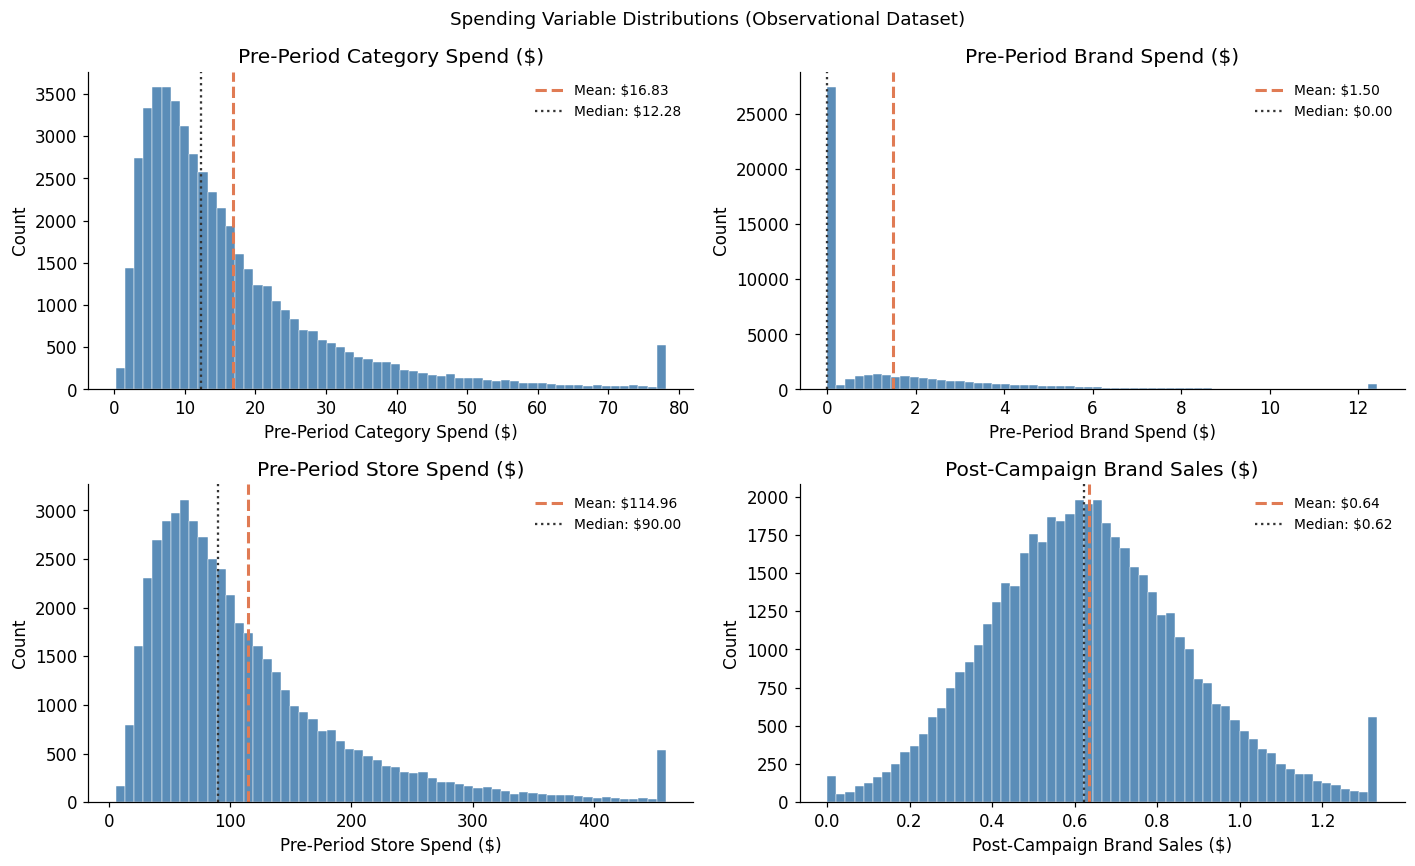

Note: all spending variables are right-skewed (lognormal) — a few high-spend
households pull the mean above the median. This is typical in CPG retail data.


In [22]:
# ── Spending variable distributions ──────────────────────────────────────────
spend_vars = [
    ('pre_52_category_spend', 'Pre-Period Category Spend ($)'),
    ('pre_52_brand_spend',    'Pre-Period Brand Spend ($)'),
    ('pre_52_store_spend',    'Pre-Period Store Spend ($)'),
    ('post_brand_sales',      'Post-Campaign Brand Sales ($)'),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, (col, label) in zip(axes.flat, spend_vars):
    data = df[col]
    # Clip extreme values for readability
    cap = data.quantile(0.99)
    ax.hist(data.clip(upper=cap), bins=60, color=CONTROL_COLOR, edgecolor='white', linewidth=0.3)
    ax.axvline(data.mean(), color=TREATED_COLOR, linestyle='--', linewidth=2,
               label=f'Mean: ${data.mean():.2f}')
    ax.axvline(data.median(), color='#333333', linestyle=':', linewidth=1.5,
               label=f'Median: ${data.median():.2f}')
    ax.set_xlabel(label)
    ax.set_ylabel('Count')
    ax.set_title(label)
    ax.legend(fontsize=9, frameon=False)

plt.suptitle('Spending Variable Distributions (Observational Dataset)', fontsize=12)
plt.tight_layout()
plt.show()

print('Note: all spending variables are right-skewed (lognormal) — a few high-spend')
print('households pull the mean above the median. This is typical in CPG retail data.')

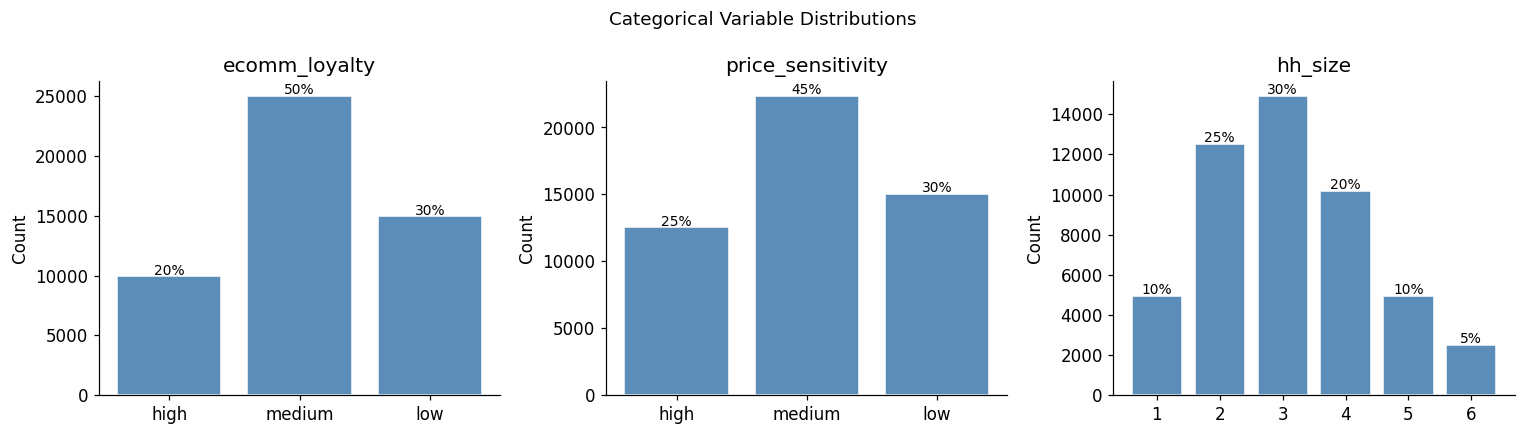

In [23]:
# ── Categorical variable distributions ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

cat_vars = [
    ('ecomm_loyalty',    ['high', 'medium', 'low']),
    ('price_sensitivity',['high', 'medium', 'low']),
    ('hh_size',          [1, 2, 3, 4, 5, 6]),
]

for ax, (col, order) in zip(axes, cat_vars):
    counts = df[col].value_counts().reindex(order)
    ax.bar(counts.index.astype(str), counts.values, color=CONTROL_COLOR, edgecolor='white')
    ax.set_title(col)
    ax.set_ylabel('Count')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 100, f'{v/len(df):.0%}', ha='center', fontsize=9)

plt.suptitle('Categorical Variable Distributions', fontsize=12)
plt.tight_layout()
plt.show()

In [24]:
# ── Brand buyer rate ──────────────────────────────────────────────────────────
buyer_rate = df['pre_52_brand_buyer'].mean()
print(f'Brand buyer rate (pre-period): {buyer_rate:.1%}')
print(f'  → {buyer_rate:.1%} of households purchased this brand in the prior 52 weeks')
print(f'  → {1-buyer_rate:.1%} are non-buyers (pre_52_brand_spend = $0)')

Brand buyer rate (pre-period): 45.2%
  → 45.2% of households purchased this brand in the prior 52 weeks
  → 54.8% are non-buyers (pre_52_brand_spend = $0)


---
## Step 4: Who Was Targeted? Understanding Selection Bias

**What we are doing:** Examine whether the decision to advertise to a household was related to that household's pre-campaign characteristics.

**Why this is the central problem:** In observational advertising data, who receives an ad is not random — it reflects a deliberate business decision. Advertisers typically target households that are:
- Already engaged with the brand or category (high loyalty)
- Likely to purchase based on past behavior (high spend)
- In demographics associated with higher conversion

If treated and control households differ *before* the campaign, then any difference we observe *after* the campaign could be due to these pre-existing differences — not the advertising.

**What to look for:**
- Does treatment rate vary systematically by loyalty tier? By spending quintile?
- Are high-spend, high-loyalty households more likely to have been targeted?
- Is the prior brand buyer rate higher among treated households?

If yes to all of the above: **selection bias is present**, and a simple before-after comparison will overstate the advertising effect.

---
## 3. Who Was Targeted? Treatment Group Characteristics

In an observational dataset, the treated and control groups are **not** randomly selected. Examining who was targeted is the first step toward understanding the selection bias we need to correct.

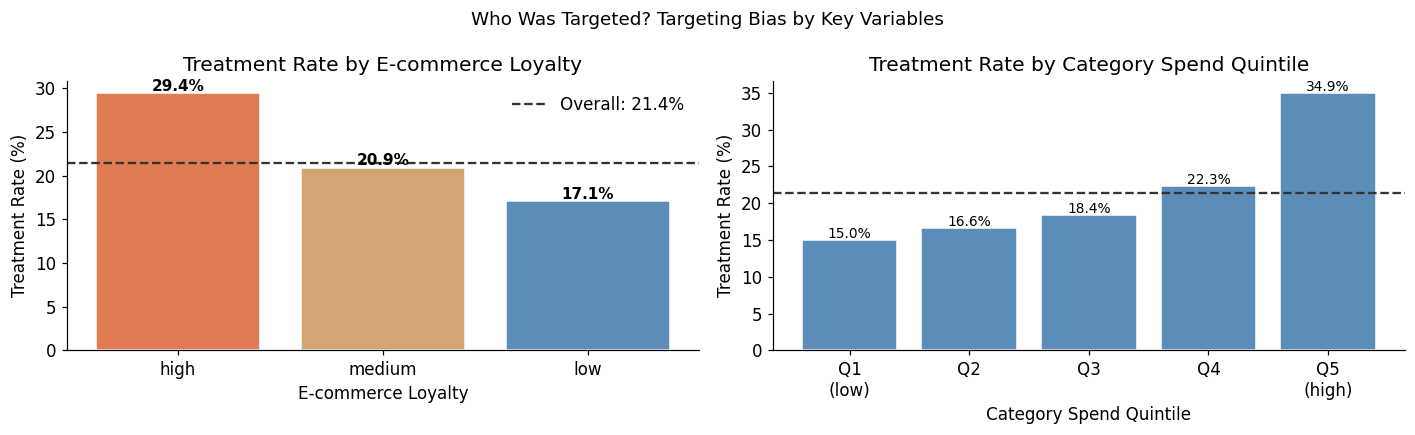

>>> The targeting is clear: high-loyalty and high-spend households were more likely targeted.
    This is a deliberate advertising strategy — but it creates selection bias in the data.


In [25]:
# ── Treatment rate by ecomm_loyalty ──────────────────────────────────────────
if len(df) == 0:
    print("Error: The dataset is empty. Please ensure 'observational_dataset.csv' is loaded successfully before running this cell.")
else:
    loyalty_order = ['high', 'medium', 'low']
    loyalty_treat = (
        df.groupby('ecomm_loyalty')['is_treated']
        .mean()
        .reindex(loyalty_order)
        .reset_index()
    )

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Treatment rate by loyalty
    ax = axes[0]
    bars = ax.bar(
        loyalty_treat['ecomm_loyalty'],
        loyalty_treat['is_treated'] * 100,
        color=[TREATED_COLOR, '#D4A574', CONTROL_COLOR],
        edgecolor='white',
    )
    ax.axhline(df['is_treated'].mean() * 100, color='#333333', linestyle='--',
               linewidth=1.5, label=f'Overall: {df["is_treated"].mean():.1%}')
    for bar, val in zip(bars, loyalty_treat['is_treated']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{val:.1%}', ha='center', fontsize=10, fontweight='bold')
    ax.set_xlabel('E-commerce Loyalty')
    ax.set_ylabel('Treatment Rate (%)')
    ax.set_title('Treatment Rate by E-commerce Loyalty')
    ax.legend(frameon=False)

    # Treatment rate by category spend quintile
    ax2 = axes[1]
    df['cat_spend_quintile'] = pd.qcut(df['pre_52_category_spend'], q=5, labels=['Q1\n(low)', 'Q2', 'Q3', 'Q4', 'Q5\n(high)'], duplicates='drop')
    quintile_treat = df.groupby('cat_spend_quintile', observed=True)['is_treated'].mean().reset_index()
    bars2 = ax2.bar(
        quintile_treat['cat_spend_quintile'].astype(str),
        quintile_treat['is_treated'] * 100,
        color=CONTROL_COLOR,
        edgecolor='white',
    )
    ax2.axhline(df['is_treated'].mean() * 100, color='#333333', linestyle='--', linewidth=1.5)
    for bar, val in zip(bars2, quintile_treat['is_treated']):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1%}', ha='center', fontsize=9)
    ax2.set_xlabel('Category Spend Quintile')
    ax2.set_ylabel('Treatment Rate (%)')
    ax2.set_title('Treatment Rate by Category Spend Quintile')

    plt.suptitle('Who Was Targeted? Targeting Bias by Key Variables', fontsize=12)
    plt.tight_layout()
    plt.show()

    print('>>> The targeting is clear: high-loyalty and high-spend households were more likely targeted.')
    print('    This is a deliberate advertising strategy — but it creates selection bias in the data.')

---
## Step 5: The Outcome Variable — How Different Do Groups Look?

**What we are doing:** Compare post-campaign brand sales between treated and control households. This is the "naive" estimate — the number you would report if you simply looked at outcomes without correcting for selection bias.

**Why this is informative but dangerous:** The difference in means is easy to compute and will be large. But as we established in Step 4, the groups were not comparable before the campaign. So any observed difference mixes together:
1. The true causal effect of advertising (what we actually want)
2. Pre-existing differences between targeted and non-targeted households (selection bias)

**What to look for:**
- How large is the gap between treated and control means?
- How does the naive estimate compare to the true ATE of $0.05?
- The bias = (naive estimate) − (true ATE) — how much does targeting inflate our apparent lift?

**Key benchmark:** The true ATE in this dataset is **$0.05** (~8% lift). Any estimate above that is bias from selection.

In [26]:
# ── Brand buyer rate by treatment status ──────────────────────────────────────
buyer_by_treat = df.groupby('is_treated')['pre_52_brand_buyer'].mean()
print('Prior brand buyer rate by treatment group:')
print(f'  Control (is_treated=0): {buyer_by_treat[0]:.1%}')
print(f'  Treated (is_treated=1): {buyer_by_treat[1]:.1%}')
print(f'  Difference:             {(buyer_by_treat[1] - buyer_by_treat[0])*100:.1f} pp')
print()
print('Treated households were more likely to have bought the brand before the campaign.')
print('This will inflate naive estimates of advertising lift.')

Prior brand buyer rate by treatment group:
  Control (is_treated=0): 45.2%
  Treated (is_treated=1): 44.9%
  Difference:             -0.3 pp

Treated households were more likely to have bought the brand before the campaign.
This will inflate naive estimates of advertising lift.


---
## Step 6: Feature–Outcome Relationships

**What we are doing:** Explore how pre-campaign variables relate to the post-campaign outcome. Understanding these relationships tells us which variables are the most important confounders — variables that jointly predict both who was targeted AND what the outcome was.

**Why this matters for causal inference:** A variable is a **confounder** if it:
1. Predicts treatment assignment (who received ads)
2. Also affects the outcome (post-campaign sales)

When a confounder is not accounted for, it creates the "pre-existing difference" that biases our estimate. By visualizing these relationships, we can identify which variables must be included in any adjustment strategy.

**What to look for:**
- Do treated households (orange) cluster at higher values on the scatter plots?
- Which loyalty tier has the highest post-campaign sales?
- How much of the correlation matrix is driven by the pre-period variables correlating with both `is_treated` and `post_brand_sales`?

---
## 4. Outcome Variable: post_brand_sales

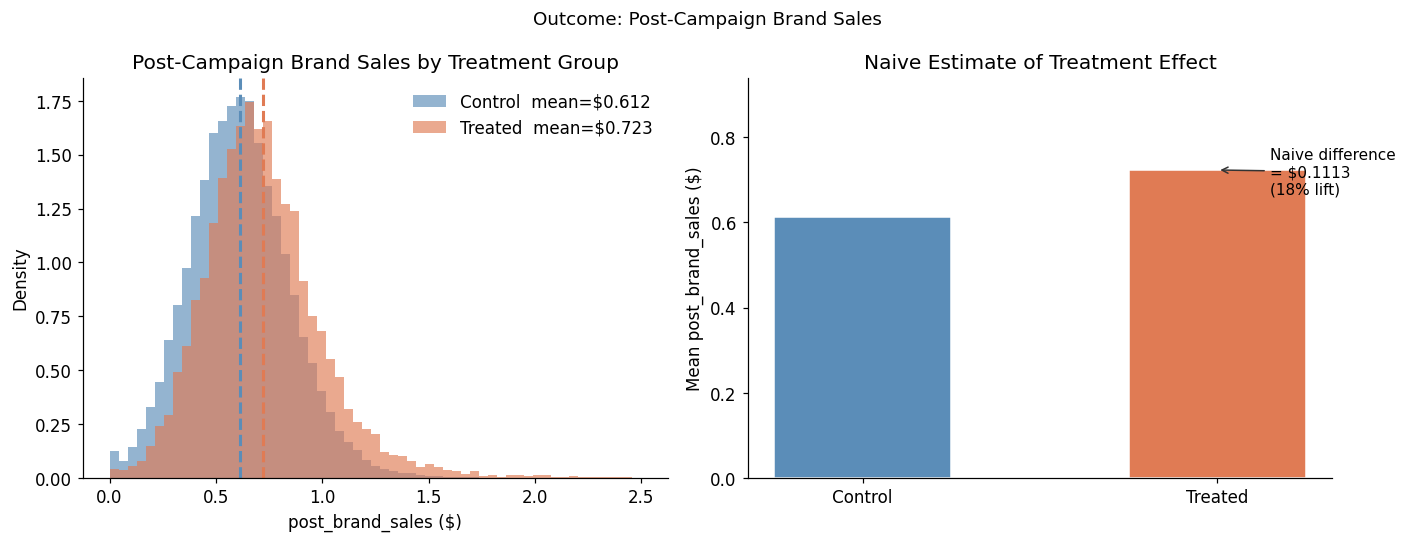

Naive ATE (difference-in-means): $0.1113  (18.2% lift)
True ATE (known from simulation): $0.0500  (~8% lift)

The naive estimate is more than double the true effect — entirely due to selection bias.
Treated households would have had higher sales even WITHOUT the advertising.


In [27]:
# ── Outcome by treatment group ────────────────────────────────────────────────
mean_t = treated['post_brand_sales'].mean()
mean_c = control['post_brand_sales'].mean()
naive_ate = mean_t - mean_c

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bins = np.linspace(0, 2.5, 60)
ax = axes[0]
ax.hist(control['post_brand_sales'], bins=bins, alpha=0.65, color=CONTROL_COLOR,
        label=f'Control  mean=${mean_c:.3f}', density=True)
ax.hist(treated['post_brand_sales'], bins=bins, alpha=0.65, color=TREATED_COLOR,
        label=f'Treated  mean=${mean_t:.3f}', density=True)
ax.axvline(mean_c, color=CONTROL_COLOR, linestyle='--', linewidth=2)
ax.axvline(mean_t, color=TREATED_COLOR, linestyle='--', linewidth=2)
ax.set_xlabel('post_brand_sales ($)')
ax.set_ylabel('Density')
ax.set_title('Post-Campaign Brand Sales by Treatment Group')
ax.legend(frameon=False)

ax2 = axes[1]
ax2.bar(
    ['Control', 'Treated'],
    [mean_c, mean_t],
    color=[CONTROL_COLOR, TREATED_COLOR],
    edgecolor='white',
    width=0.5,
)
ax2.annotate(
    f'Naive difference\n= ${naive_ate:.4f}\n({naive_ate/mean_c:.0%} lift)',
    xy=(1, mean_t), xytext=(1.15, (mean_t + mean_c) / 2),
    arrowprops=dict(arrowstyle='->', color='#333333'),
    fontsize=10,
)
ax2.set_ylabel('Mean post_brand_sales ($)')
ax2.set_title('Naive Estimate of Treatment Effect')
ax2.set_ylim(0, mean_t * 1.3)

plt.suptitle('Outcome: Post-Campaign Brand Sales', fontsize=12)
plt.tight_layout()
plt.show()

print(f'Naive ATE (difference-in-means): ${naive_ate:.4f}  ({naive_ate/mean_c:.1%} lift)')
print(f'True ATE (known from simulation): $0.0500  (~8% lift)')
print()
print('The naive estimate is more than double the true effect — entirely due to selection bias.')
print('Treated households would have had higher sales even WITHOUT the advertising.')

---
## 5. Relationships Between Features and the Outcome

Understanding how pre-period variables relate to the outcome helps us identify which variables are important for controlling selection bias.

---
## Step 7: The Bias Problem Quantified

**What we are doing:** Build a summary table that directly compares treated and control households on all pre-campaign variables. This table makes the selection bias concrete and quantifiable.

**Why this is important:** This table answers the question: "How different were the groups *before* the campaign?" If they were already very different, a naive post-campaign comparison will be severely biased. The table also shows the final bias calculation — the difference between the naive estimate and the true ATE.

**What to look for:**
- Across all pre-period variables, are the differences systematically in one direction (treated > control)?
- How large is the difference in `pre_52_category_spend` — the variable that was most strongly linked to targeting?
- What is the total implied bias in the naive ATE?

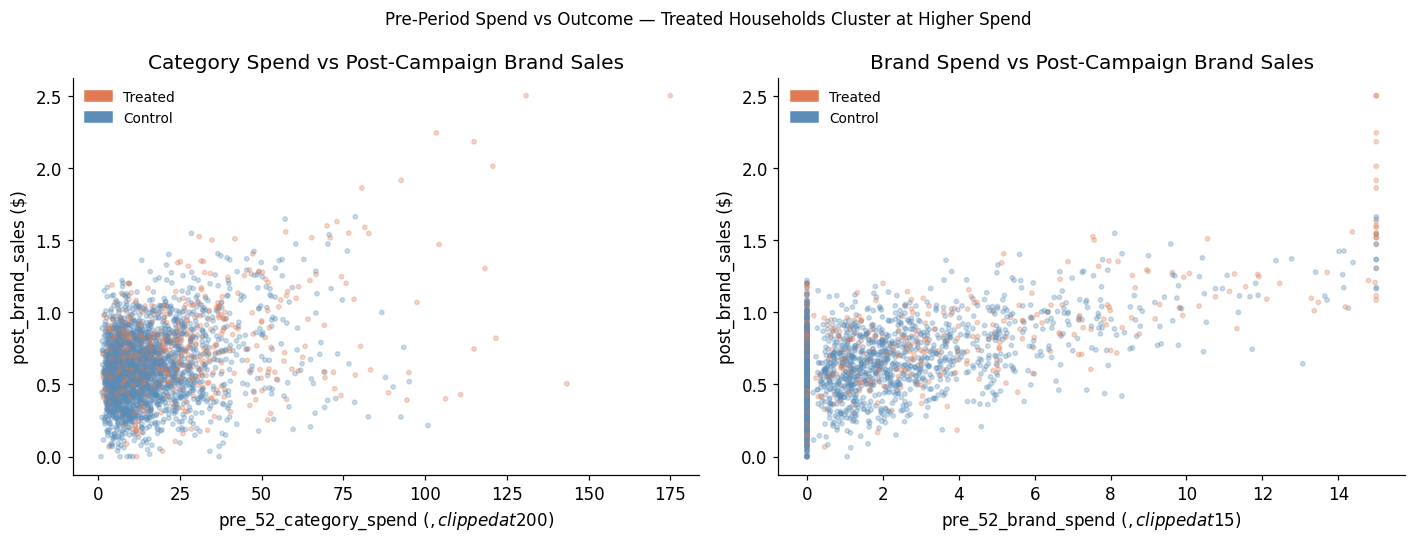

In [28]:
# ── Scatter: category spend vs post_brand_sales ───────────────────────────────
# Sample for readability
sample = df.sample(3000, random_state=42)
colors_sample = [TREATED_COLOR if t else CONTROL_COLOR for t in sample['is_treated']]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.scatter(
    sample['pre_52_category_spend'].clip(upper=200),
    sample['post_brand_sales'].clip(upper=2.5),
    c=colors_sample, alpha=0.3, s=8,
)
ax.set_xlabel('pre_52_category_spend ($, clipped at $200)')
ax.set_ylabel('post_brand_sales ($)')
ax.set_title('Category Spend vs Post-Campaign Brand Sales')
# Legend
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color=TREATED_COLOR, label='Treated'),
    Patch(color=CONTROL_COLOR, label='Control'),
], frameon=False, fontsize=9)

ax2 = axes[1]
ax2.scatter(
    sample['pre_52_brand_spend'].clip(upper=15),
    sample['post_brand_sales'].clip(upper=2.5),
    c=colors_sample, alpha=0.3, s=8,
)
ax2.set_xlabel('pre_52_brand_spend ($, clipped at $15)')
ax2.set_ylabel('post_brand_sales ($)')
ax2.set_title('Brand Spend vs Post-Campaign Brand Sales')
ax2.legend(handles=[
    Patch(color=TREATED_COLOR, label='Treated'),
    Patch(color=CONTROL_COLOR, label='Control'),
], frameon=False, fontsize=9)

plt.suptitle('Pre-Period Spend vs Outcome — Treated Households Cluster at Higher Spend', fontsize=11)
plt.tight_layout()
plt.show()

##Summary: What We learned from this EDA


| Finding | Implication |
|---|---|
| Spending variables are right-skewed | Models should account for non-normality; check sensitivity to outliers |
| Treatment is not random | Simple group comparison will be biased |
| Treated HHs had higher baseline brand spend | Pre-existing behavior inflates naive lift |
| Naive ATE (~$0.11) >> True ATE ($0.05) | ~$0.06 of the observed lift is selection bias, not advertising |
| Pre-period spend correlates with both treatment and outcome | These are the key confounders to control for |



### The Core Lesson

The observational dataset illustrates the central challenge of advertising measurement: **treated and control households are not comparable**. The firm targeted households that were already more likely to buy — so even without any advertising, we would expect treated households to outperform control households.

The naive approach — simply comparing post-campaign outcomes — mistakes this pre-existing difference for advertising effectiveness. This leads to:
- Overestimation of incremental lift
- Overestimation of incremental ROAS
- Potentially incorrect budget decisions

### What Comes Next

To recover a credible causal estimate from this observational data, we need to:
1. **Model the propensity score** — estimate the probability each household had of being targeted (notebook 3)
2. **Match treated and control households** on their propensity scores — find control households that "look like" treated households (notebook 4)

Even after matching, we will see that some residual bias remains — because the targeting also depended on an **unobserved variable** that we do not have in our data. This limitation is fundamental to observational causal inference.

The **randomized holdout experiment** (notebooks 2 and 5) avoids this problem entirely by design.

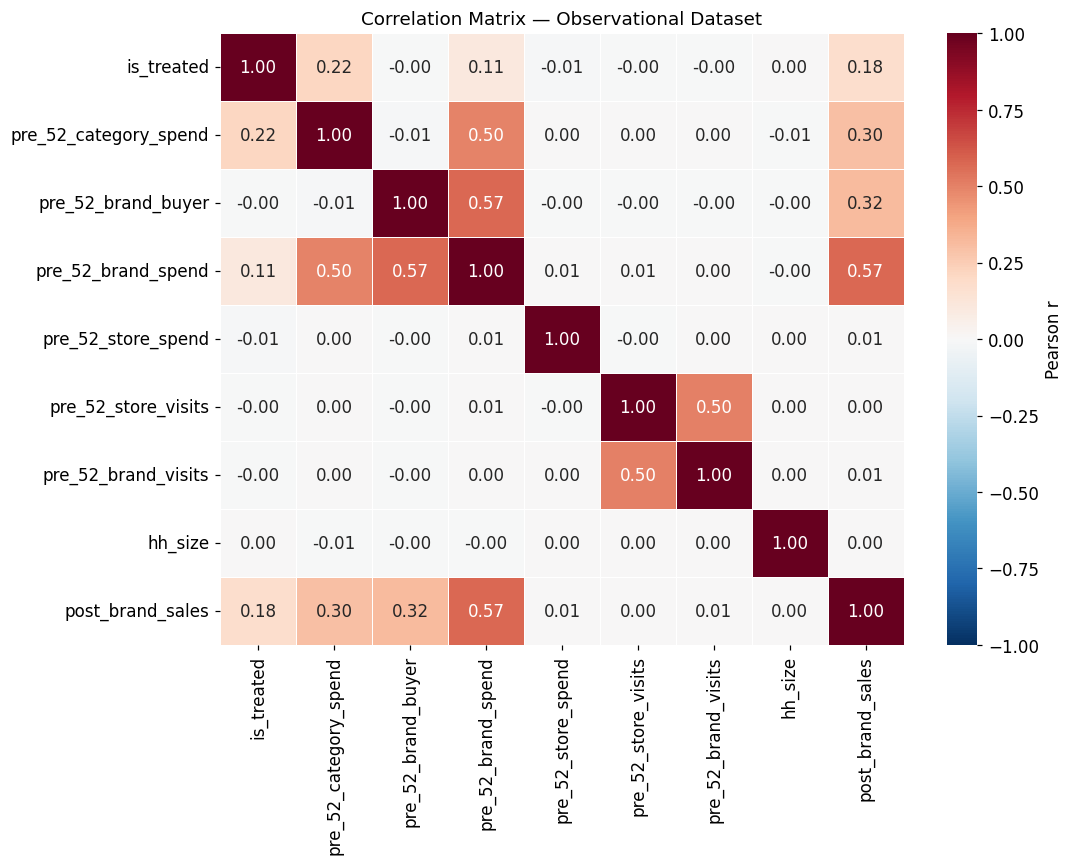

Variables most correlated with is_treated (targeting drivers):
  pre_52_category_spend           |r| = 0.217
  post_brand_sales                |r| = 0.179
  pre_52_brand_spend              |r| = 0.108
  pre_52_store_spend              |r| = 0.009
  pre_52_store_visits             |r| = 0.004
  pre_52_brand_buyer              |r| = 0.003
  pre_52_brand_visits             |r| = 0.001
  hh_size                         |r| = 0.001


In [31]:
# ── Correlation heatmap ───────────────────────────────────────────────────────
numeric_cols = [
    'is_treated',
    'pre_52_category_spend',
    'pre_52_brand_buyer',
    'pre_52_brand_spend',
    'pre_52_store_spend',
    'pre_52_store_visits',
    'pre_52_brand_visits',
    'hh_size',
    'post_brand_sales',
]

corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr,
    ax=ax,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson r'},
)
ax.set_title('Correlation Matrix — Observational Dataset', fontsize=12)
plt.tight_layout()
plt.show()

print('Variables most correlated with is_treated (targeting drivers):')
treat_corr = corr['is_treated'].drop('is_treated').abs().sort_values(ascending=False)
for col, val in treat_corr.items():
    print(f'  {col:<30}  |r| = {val:.3f}')

---
## 6. The Problem in Plain Language

The table below summarizes the core bias problem:

In [32]:
# ── Pre-treatment differences between groups ──────────────────────────────────
compare_cols = [
    'pre_52_category_spend',
    'pre_52_brand_buyer',
    'pre_52_brand_spend',
    'pre_52_store_spend',
    'pre_52_store_visits',
    'post_brand_sales',
]

summary = pd.DataFrame({
    'Control Mean': control[compare_cols].mean().round(3),
    'Treated Mean': treated[compare_cols].mean().round(3),
})
summary['Difference'] = (summary['Treated Mean'] - summary['Control Mean']).round(3)
summary['% Diff'] = ((summary['Difference'] / summary['Control Mean']) * 100).round(1)

print('Pre-treatment and outcome differences: Treated vs Control')
print('=' * 70)
print(summary.to_string())
print()
print('Bottom line: treated households have higher pre-period spending across the board.')
print('This is why simply comparing post-campaign sales overstates the advertising effect.')
print()
print(f'Naive ATE:  ${naive_ate:.4f}  (what we observe)')
print(f'True ATE:   $0.0500  (what actually happened)')
print(f'Bias:       ${naive_ate - 0.05:.4f}  (due to targeting pre-existing heavy buyers)')

Pre-treatment and outcome differences: Treated vs Control
                       Control Mean  Treated Mean  Difference  % Diff
pre_52_category_spend        14.980        23.587       8.607    57.5
pre_52_brand_buyer            0.452         0.449      -0.003    -0.7
pre_52_brand_spend            1.338         2.103       0.765    57.2
pre_52_store_spend          115.380       113.411      -1.969    -1.7
pre_52_store_visits          25.975        25.928      -0.047    -0.2
post_brand_sales              0.612         0.723       0.111    18.1

Bottom line: treated households have higher pre-period spending across the board.
This is why simply comparing post-campaign sales overstates the advertising effect.

Naive ATE:  $0.1113  (what we observe)
True ATE:   $0.0500  (what actually happened)
Bias:       $0.0613  (due to targeting pre-existing heavy buyers)


---
## Summary

What we learned from this EDA:

1. **Spending variables are right-skewed** — a small number of households account for a large share of spend. Models should account for this.
2. **Treatment is not random** — high-loyalty, high-category-spend households were much more likely to be targeted.
3. **Treated households had higher baseline brand spend** — before the campaign even started, they were heavier brand buyers.
4. **The naive outcome difference (~$0.11) is more than twice the true effect ($0.05)** — the rest is selection bias, not advertising lift.
5. **Pre-period brand and category spend are the strongest predictors of both treatment and outcome** — these are the key variables to control for in propensity score matching.

**Next step:** Run `propensity_score_notebook.ipynb` to model the propensity of treatment and then `propensity_matching_notebook.ipynb` to estimate the causal effect.